In [1]:
#import libraries
import pandas as pd

from mlxtend.frequent_patterns import (
    apriori,
    association_rules
)

import matplotlib.pyplot as plt

In [7]:
#load dataset
pd.read_csv(r"D:\vs\final project1\Community Healthcare MultiSymptomsDisease Diagnostic Dataset.csv")

,disease,symptom_cough,symptom_dry_cough,symptom_productive_cough,symptom_shortness_of_breath,symptom_wheezing,symptom_chest_tightness,symptom_sore_throat,symptom_runny_nose,symptom_nasal_congestion,...,rare_symptom_tall_stature_rare,rare_symptom_hyperextensible_skin_rare,rare_symptom_joint_hypermobility_rare,rare_symptom_macroglossia_rare,rare_symptom_hearing_loss_early_onset_rare,rare_symptom_developmental_delay_rare,rare_symptom_proximal_muscle_weakness_rare,rare_symptom_bulbar_symptoms_rare,rare_symptom_respiratory_failure_rare,rare_symptom_renal_cysts_rare
0,Hyperthyroidism,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Coronary_Artery_Disease,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,Irritable_Bowel_Syndrome,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Irritable_Bowel_Syndrome,0,0,0,0,0,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
4,Obesity,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,Obesity,1,1,1,1,1,1,1,0,1,...,0,0,1,0,0,0,0,0,0,0
99996,Hypertension,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
99997,Hyperthyroidism,1,1,0,1,0,1,0,1,1,...,0,0,0,0,0,0,0,0,0,0
99998,Obesity,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0


In [8]:
df = pd.read_csv(r"D:\vs\final project1\Community Healthcare MultiSymptomsDisease Diagnostic Dataset.csv")

In [9]:
#inspect dataset
df.shape

(100000, 175)

In [10]:
df.head()

,disease,symptom_cough,symptom_dry_cough,symptom_productive_cough,symptom_shortness_of_breath,symptom_wheezing,symptom_chest_tightness,symptom_sore_throat,symptom_runny_nose,symptom_nasal_congestion,...,rare_symptom_tall_stature_rare,rare_symptom_hyperextensible_skin_rare,rare_symptom_joint_hypermobility_rare,rare_symptom_macroglossia_rare,rare_symptom_hearing_loss_early_onset_rare,rare_symptom_developmental_delay_rare,rare_symptom_proximal_muscle_weakness_rare,rare_symptom_bulbar_symptoms_rare,rare_symptom_respiratory_failure_rare,rare_symptom_renal_cysts_rare
0,Hyperthyroidism,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Coronary_Artery_Disease,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,Irritable_Bowel_Syndrome,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Irritable_Bowel_Syndrome,0,0,0,0,0,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
4,Obesity,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [11]:
df.columns.tolist()

['disease',
 'symptom_cough',
 'symptom_dry_cough',
 'symptom_productive_cough',
 'symptom_shortness_of_breath',
 'symptom_wheezing',
 'symptom_chest_tightness',
 'symptom_sore_throat',
 'symptom_runny_nose',
 'symptom_nasal_congestion',
 'symptom_sinus_pain',
 'symptom_loss_of_smell',
 'symptom_loss_of_taste',
 'symptom_pleuritic_chest_pain',
 'symptom_hemoptysis',
 'symptom_exercise_dyspnea',
 'symptom_orthopnea',
 'symptom_chest_pain',
 'symptom_exertional_chest_pain',
 'symptom_palpitations',
 'symptom_orthopnea_symptom',
 'symptom_paroxysmal_nocturnal_dyspnea',
 'symptom_leg_swelling',
 'symptom_exercise_intolerance',
 'symptom_syncope',
 'symptom_fatigue_on_exertion',
 'symptom_resting_tachycardia',
 'symptom_bradycardia',
 'symptom_clammy_skin',
 'symptom_cyanosis',
 'symptom_peripheral_edema',
 'symptom_claudication',
 'symptom_headache',
 'symptom_migraine_symptom',
 'symptom_dizziness',
 'symptom_vertigo',
 'symptom_seizures_symptom',
 'symptom_focal_weakness',
 'symptom_numb

In [12]:
#Remove target column(focus on symptom relationships first)
transactions = df.drop(
    columns=['disease'])

In [13]:
#Remove rare symptoms(rule explosion and noisy associations)
core_cols = [

    col for col in transactions.columns

    if not col.startswith(
        'rare_'
    )
]

transactions = transactions[
    core_cols
]

In [14]:
#verify binary values
for col in transactions.columns:

    print(
        col,
        transactions[col].unique()
    )

symptom_cough [0 1]
symptom_dry_cough [1 0]
symptom_productive_cough [0 1]
symptom_shortness_of_breath [0 1]
symptom_wheezing [0 1]
symptom_chest_tightness [0 1]
symptom_sore_throat [0 1]
symptom_runny_nose [0 1]
symptom_nasal_congestion [0 1]
symptom_sinus_pain [0 1]
symptom_loss_of_smell [0 1]
symptom_loss_of_taste [0 1]
symptom_pleuritic_chest_pain [0 1]
symptom_hemoptysis [0 1]
symptom_exercise_dyspnea [0 1]
symptom_orthopnea [0 1]
symptom_chest_pain [0 1]
symptom_exertional_chest_pain [1 0]
symptom_palpitations [1 0]
symptom_orthopnea_symptom [1 0]
symptom_paroxysmal_nocturnal_dyspnea [1 0]
symptom_leg_swelling [0 1]
symptom_exercise_intolerance [1 0]
symptom_syncope [1 0]
symptom_fatigue_on_exertion [1 0]
symptom_resting_tachycardia [0 1]
symptom_bradycardia [1 0]
symptom_clammy_skin [0 1]
symptom_cyanosis [1 0]
symptom_peripheral_edema [0 1]
symptom_claudication [1 0]
symptom_headache [0 1]
symptom_migraine_symptom [1 0]
symptom_dizziness [1 0]
symptom_vertigo [0 1]
symptom_seiz

In [15]:
#convert to boolean
transactions = transactions.astype(bool)

In [21]:
#Check final shape
print(
    transactions.shape
)

(20000, 18)


In [22]:
#Generate frequent itemsets
selected_cols = [

    'symptom_cough',
    'symptom_shortness_of_breath',
    'symptom_wheezing',
    'symptom_chest_pain',
    'symptom_palpitations',
    'symptom_fatigue',
    'symptom_fever',
    'symptom_chills',
    'symptom_headache',
    'symptom_dizziness',
    'symptom_nausea',
    'symptom_vomiting',
    'symptom_abdominal_pain',
    'symptom_joint_pain_symptom',
    'symptom_myalgia',
    'symptom_anxiety_symptom',
    'symptom_low_mood',
    'symptom_insomnia'
]

transactions = df[
    selected_cols
]

transactions = transactions.sample(
    n=20000,
    random_state=42
)

transactions = transactions.astype(bool)

frequent_itemsets = apriori(

    transactions,

    min_support=0.05,

    use_colnames=True,

    low_memory=True
)

In [23]:
#Inspect frequent itemsets
print(
    frequent_itemsets.head()
)

print(
    frequent_itemsets.shape
)

   support                       itemsets
0  0.25360                (symptom_cough)
1  0.25235  (symptom_shortness_of_breath)
2  0.25280             (symptom_wheezing)
3  0.21980           (symptom_chest_pain)
4  0.21650         (symptom_palpitations)
(136, 2)


In [24]:
#Sort itemsets
frequent_itemsets = frequent_itemsets.sort_values(

    by='support',

    ascending=False
)

print(
    frequent_itemsets.head(10)
)

    support                       itemsets
14  0.25580              (symptom_myalgia)
0   0.25360                (symptom_cough)
7   0.25325               (symptom_chills)
2   0.25280             (symptom_wheezing)
5   0.25280              (symptom_fatigue)
6   0.25250                (symptom_fever)
1   0.25235  (symptom_shortness_of_breath)
13  0.25080   (symptom_joint_pain_symptom)
12  0.23755       (symptom_abdominal_pain)
11  0.23315             (symptom_vomiting)


In [25]:
#Generate Association rules
from mlxtend.frequent_patterns import association_rules

rules = association_rules(

    frequent_itemsets,

    metric="confidence",

    min_threshold=0.6
)

In [26]:
#Inspect rules
print(
    rules.head()
)

print(
    rules.shape
)

                    antecedents                   consequents  \
0             (symptom_myalgia)             (symptom_fatigue)   
1             (symptom_fatigue)             (symptom_myalgia)   
2  (symptom_joint_pain_symptom)             (symptom_fatigue)   
3             (symptom_fatigue)  (symptom_joint_pain_symptom)   
4             (symptom_myalgia)  (symptom_joint_pain_symptom)   

   antecedent support  consequent support  support  confidence      lift  \
0              0.2558              0.2528  0.15955    0.623729  2.467284   
1              0.2528              0.2558  0.15955    0.631131  2.467284   
2              0.2508              0.2528  0.15895    0.633772  2.507009   
3              0.2528              0.2508  0.15895    0.628758  2.507009   
4              0.2558              0.2508  0.15845    0.619429  2.469814   

   representativity  leverage  conviction  zhangs_metric   jaccard  certainty  \
0               1.0  0.094884    1.985805       0.799108  0.457098   0.

In [27]:
#Sort best rules
rules = rules.sort_values(

    by='lift',

    ascending=False
)

In [30]:
#Display important rules
top_rules = rules[
    [
        'antecedents',
        'consequents',
        'support',
        'confidence',
        'lift'
    ]
].head(20)

print(top_rules)

                                           antecedents  \
127  (symptom_myalgia, symptom_joint_pain_symptom, ...   
124  (symptom_chills, symptom_joint_pain_symptom, s...   
125  (symptom_fever, symptom_myalgia, symptom_joint...   
130  (symptom_myalgia, symptom_fatigue, symptom_chi...   
126  (symptom_fever, symptom_joint_pain_symptom, sy...   
128  (symptom_fever, symptom_myalgia, symptom_fatigue)   
122  (symptom_fever, symptom_joint_pain_symptom, sy...   
129   (symptom_fever, symptom_chills, symptom_fatigue)   
123  (symptom_myalgia, symptom_joint_pain_symptom, ...   
131   (symptom_fever, symptom_myalgia, symptom_chills)   
133        (symptom_anxiety_symptom, symptom_insomnia)   
132        (symptom_anxiety_symptom, symptom_low_mood)   
134               (symptom_low_mood, symptom_insomnia)   
72                    (symptom_fever, symptom_fatigue)   
75                   (symptom_myalgia, symptom_chills)   
71                    (symptom_fever, symptom_myalgia)   
76            

In [31]:
#Create Readable Rules
rules['rule'] = rules.apply(

    lambda row:

    str(row['antecedents'])
    +
    " → "
    +
    str(row['consequents']),

    axis=1
)

In [32]:
#Clean Output
print(

    rules[
        [
            'rule',
            'support',
            'confidence',
            'lift'
        ]
    ].head(10)
)

                                                  rule  support  confidence  \
127  frozenset({'symptom_myalgia', 'symptom_joint_p...   0.0806    0.667219   
124  frozenset({'symptom_chills', 'symptom_joint_pa...   0.0806    0.668880   
125  frozenset({'symptom_fever', 'symptom_myalgia',...   0.0806    0.662557   
130  frozenset({'symptom_myalgia', 'symptom_fatigue...   0.0806    0.658228   
126  frozenset({'symptom_fever', 'symptom_joint_pai...   0.0806    0.670828   
128  frozenset({'symptom_fever', 'symptom_myalgia',...   0.0806    0.657155   
122  frozenset({'symptom_fever', 'symptom_joint_pai...   0.0806    0.659574   
129  frozenset({'symptom_fever', 'symptom_chills', ...   0.0806    0.661741   
123  frozenset({'symptom_myalgia', 'symptom_joint_p...   0.0806    0.653955   
131  frozenset({'symptom_fever', 'symptom_myalgia',...   0.0806    0.661741   

         lift  
127  4.241694  
124  4.224059  
125  4.210718  
130  4.209964  
126  4.204501  
128  4.195050  
122  4.193099  
12

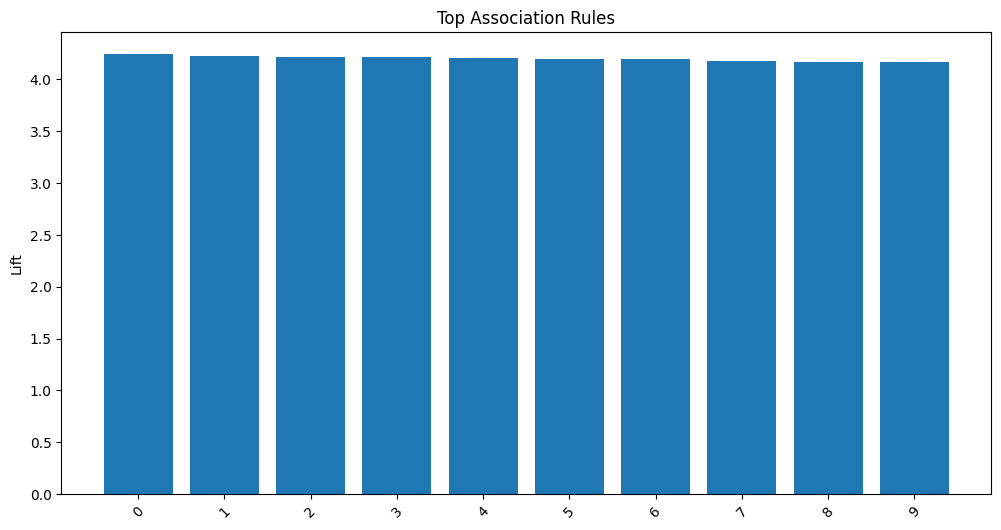

In [33]:
#Visualization
import matplotlib.pyplot as plt

top10 = rules.head(10)

plt.figure(figsize=(12,6))

plt.bar(

    range(len(top10)),

    top10['lift']
)

plt.xticks(

    range(len(top10)),

    rotation=45
)

plt.ylabel("Lift")

plt.title(
    "Top Association Rules"
)

plt.show()

In [34]:
#Save results
rules.to_csv(

    "association_rules.csv",

    index=False
)